In [1]:
#Imports
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from subprocess import run, PIPE
import sys
import os
import gc
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator
import xarray as xr
import netCDF4 as nc
import pandas as pd
import cartopy.feature as cfeature

from scipy.stats import linregress
from scipy.stats import ttest_ind, ttest_ind_from_stats


from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library

import dask.distributed
import multiprocessing
from subprocess import run, PIPE
import sys
import os
import matplotlib.ticker as ticker

In [2]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 4
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 16, number of workers: 4, processes: False


In [3]:
icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_zoom9_dry_spell_annual_global.nc')['__xarray_dataarray_variable__']
ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_zoom9_dry_spell_annual_global.nc')['__xarray_dataarray_variable__']
cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/CESM2_ensmean_2021-2049_dry_spell_global.nc')['__xarray_dataarray_variable__']


In [4]:
ifs_zoom9_hist = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_zoom9_1991-2019_dry_spell_annual_global.nc')['__xarray_dataarray_variable__']
cesm2_hist = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/CESM2_ensmean_1991-2019_dry_spell_global.nc')['__xarray_dataarray_variable__']


In [5]:
icon_zoom9_beg = icon_zoom9[0:10,:]
ifs_zoom9_beg = ifs_zoom9[0:10,:]
cesm2_beg = cesm2[0:10,:]

In [6]:
icon_zoom9_end = icon_zoom9[19:29,:]
ifs_zoom9_end = ifs_zoom9[19:29,:]
cesm2_end = cesm2[19:29,:]

In [7]:
ifs_zoom9_mean = ifs_zoom9.mean(dim='year')
cesm2_mean = cesm2.mean(dim='year')

ifs_zoom9_hist_mean = ifs_zoom9_hist.mean(dim='year')
cesm2_hist_mean = cesm2_hist.mean(dim='year')


In [8]:
icon_zoom9_beg_mean = icon_zoom9_beg.mean(dim='year')
ifs_zoom9_beg_mean = ifs_zoom9_beg.mean(dim='year')
cesm2_beg_mean = cesm2_beg.mean(dim='year')

icon_zoom9_end_mean = icon_zoom9_end.mean(dim='year')
ifs_zoom9_end_mean = ifs_zoom9_end.mean(dim='year')
cesm2_end_mean = cesm2_end.mean(dim='year')

In [9]:
icon_zoom9_change = ((icon_zoom9_end_mean-icon_zoom9_beg_mean)/icon_zoom9_beg_mean) * 100
ifs_zoom9_change = ((ifs_zoom9_end_mean-ifs_zoom9_beg_mean)/ifs_zoom9_beg_mean) * 100
cesm2_change = ((cesm2_end_mean-cesm2_beg_mean)/cesm2_beg_mean) * 100

In [10]:
ifs_zoom9_hist_change = ((ifs_zoom9_mean-ifs_zoom9_hist_mean)/ifs_zoom9_hist_mean) * 100
cesm2_hist_change = ((cesm2_mean-cesm2_hist_mean)/cesm2_hist_mean) * 100

In [12]:
ifs_zoom9_t, ifs_zoom9_pvalue = ttest_ind(ifs_zoom9_beg, ifs_zoom9_end, equal_var=False)
icon_zoom9_t, icon_zoom9_pvalue = ttest_ind(icon_zoom9_beg, icon_zoom9_end, equal_var=False)
cesm2_t, cesm2_pvalue = ttest_ind(cesm2_beg, cesm2_end, equal_var=False)



In [13]:
print(cesm2_pvalue.min())

2.633326630309977e-07


In [14]:
ifs_zoom9_hist_t, ifs_zoom9_hist_pvalue = ttest_ind(ifs_zoom9_hist, ifs_zoom9, equal_var=False)
cesm2_hist_t, cesm2_hist_pvalue = ttest_ind(cesm2_hist, cesm2, equal_var=False)


---
## Plotting

In [15]:
# some hand written plot scripts
import numpy as np
# import sys
# sys.path.append('/home/b/b381815/python_functions/')
import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from healpix_plot import default_plot, get_listed_colormap, get_diverging_colormap
from healpix_plot_hatches import default_plot_hatch
import easygems.healpix as egh

# from healpix_functions import change_zoom_level

mpl.rc('font', **{'size': 16})
proj = ccrs.Mollweide()

In [16]:
def default_plot(
    data, 
    cmap='viridis', 
    ax='Mollweide', 
    add_coastlines=False, 
    add_rivers_lakes=False,
    topography=None,
    fill_lakes=True,
    add_colorbar=True, 
    levels=None,
    extend='neither',
    add_gridlines=False,
    dpi=300, 
    proj_kwargs={},
    cbar_kwargs={}, 
    rivers_lakes_kwargs={},
    topography_kwargs={},
    coastline_kwargs={},
    grid_kwargs={},
    **kwargs
):
    """

    Parameters
    ----------
    data : np.ndarray, shape (N,)
        Needs to be on a healpix grid, i.e., N needs to be divisibel by 12 * (2**zoom)**2
    cmap : string, optional, by default 'viridis'
    ax : string or cartopy.ccrs, optional, by default 'Mollweide'
        Possible string values:
        - 'Mollweide'
        - 'PlateCarree'
        - 'Orthographic'
    add_coaslines : bool, optional, by default False
    add_rivers_lakes : bool, optional, by default False
    fill_lakes  bool, optional, by default True
        Only relevent if `add_rivers_lakes=True`. Whether to plot shading within lakes
        this makes them better visible but might hinder seeing the variable shading
    topography : np.ndarray, shape (N,), optional, by default None
        Plot elevation contourlines based on the data passed.
    add_colorbar : bool, optional, by default True
    levels : np.ndarray, optional, by default None
        Can be used to set manual (non equidistant) color levels
    extend : string, optional, one of {'neither', 'min', 'max', 'both'}, by default 'neither'
    add_gridlines : bool, optional, by default False
    dpi : int, optional, by default 150
        Plot resolution. NOTE: sometimes artifacts apear around the zero meridian, changing
        the resoltion might solve this. 
    proj_kwargs : dict, optional
        Keyword arguments passed on to ccrs.<Projection>. Only relevent if ax is a string
        specifying a projection. The allowed values depend on the projection:
        - 'Mollweide': 'central_longitude'
        - 'PlateCarree': 'central_longitude'
        - 'Orthographic': 'central_longitude', 'central_latitude'
    cbar_kwargs : dict, optional
        Keyword arguments passed on to `plt.colorbar`
    coastline_kwargs : dict, optional
        Keyword arguments passed on to `ax.coastlines`
    topography_kwargs : dict, optional
        Keyword arguments passed on to `ax.contour`
    grid_kwargs : dict, optional
        Keyword arguments apssed on to `ax.gridlines`
    **kwargs : optional
        Keyword arguments passed on to `ax.imshow`

    Returns
    -------
    fig, ax, map_: tuple

    Additional information
    ----------------------
    List of cartopy projections: https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html
    """
    if isinstance(ax, str):
        proj = getattr(ccrs, ax)(**proj_kwargs)
        # increase transform resolution via
        # https://stackoverflow.com/questions/59020032/how-to-plot-a-filled-polygon-on-a-map-in-cartopy
        proj._threshold /= 1000.
        fig, ax = plt.subplots(
            figsize=(20, 10), 
            dpi=dpi, 
            subplot_kw={'projection': proj},
        )
        ax.set_global()
    else:
        fig = plt.gcf()
        
    if add_coastlines:
        defaults = {'color': 'gray', 'lw': .5}
        defaults.update(coastline_kwargs)
        ax.coastlines(**defaults)

    if add_rivers_lakes:
        defaults = dict(
            alpha=1,
            facecolor='none',                
            edgecolor='cornflowerblue', 
            color='cornflowerblue', 
            linewidth=.5,
        )
        defaults.update(rivers_lakes_kwargs)
        if fill_lakes:
            ax.add_feature(
                cfeature.LAKES.with_scale('50m'), 
                alpha=.2,
                facecolor='cornflowerblue',                
                edgecolor='none', 
            )
        ax.add_feature(
            cfeature.LAKES.with_scale('50m'), 
            # alpha=1,
            # facecolor='none',                
            # edgecolor='cornflowerblue', 
            **defaults
        )
        ax.add_feature(
            cfeature.RIVERS,
            # color='cornflowerblue',
            # alpha=1,
            **defaults
        )

    if topography is not None:
        defaults = dict(
            colors='gray',
            levels=range(1000, 10_000, 1000),
            linewidths=.5,
        )
        defaults.update(topography_kwargs)
        
        _, _, nx, ny = np.array(ax.bbox.bounds, dtype=int)
        xlims = ax.get_xlim()
        ylims = ax.get_ylim() 
        im = egh.healpix_resample(
            topography, 
            xlims, ylims, 
            nx, ny, 
            ax.projection, 
            method='linear', 
            nest=True)
        
        map_ = ax.contour(
            im, 
            extent=xlims + ylims, 
            origin="lower",
            **defaults
        )

    if levels is not None:
        if isinstance(cmap, str):
            cmap = get_listed_colormap(levels, cmap, extend)
            kwargs.update({
                'vmin': levels[0], 
                'vmax': levels[-1],
        })
        else: 
            if isinstance(cmap, mpl.colors.ListedColormap):  # convert back to color list 
                if extend == 'max':
                    cmap = np.concatenate([cmap.colors, [cmap.get_over()]])
                elif extend == 'min':
                    cmap = np.concatenate([[cmap.get_under()], cmap.colors])
                elif extend == 'both':
                    cmap = np.concatenate([[cmap.get_under()], cmap.colors, [cmap.get_over()]])
                else:
                    cmap = cmap.colors
                    
            cmap, norm = mpl.colors.from_levels_and_colors(levels, cmap, extend=extend)
            kwargs.update({
            'norm': norm, 
            })
        cbar_kwargs.update({
            'ticks': levels,
            # 'boundaries': np.arange(len(levels)),
        })
    
    _, _, nx, ny = np.array(ax.bbox.bounds, dtype=int)
    xlims = ax.get_xlim()
    ylims = ax.get_ylim()

    im = egh.healpix_resample(
        data, 
        xlims, ylims, 
        nx, ny, 
        ax.projection, 
        method='nearest', 
        nest=True,
    )
   
    map_ = ax.imshow(
        im, 
        extent=xlims + ylims, 
        origin="lower", 
        cmap=cmap, 
        interpolation='none',
        **kwargs,
        rasterized=True
    )

    if add_gridlines:
        ax.gridlines(**grid_kwargs)

    if add_colorbar:
        #plt.colorbar(map_, ax=ax,shrink=.8, fraction=.03, extend=extend, **cbar_kwargs)
        plt.colorbar(map_, ax=ax,shrink=1.2,pad=0.05, fraction=.08, extend=extend,orientation='horizontal', **cbar_kwargs)

    return fig, ax, map_

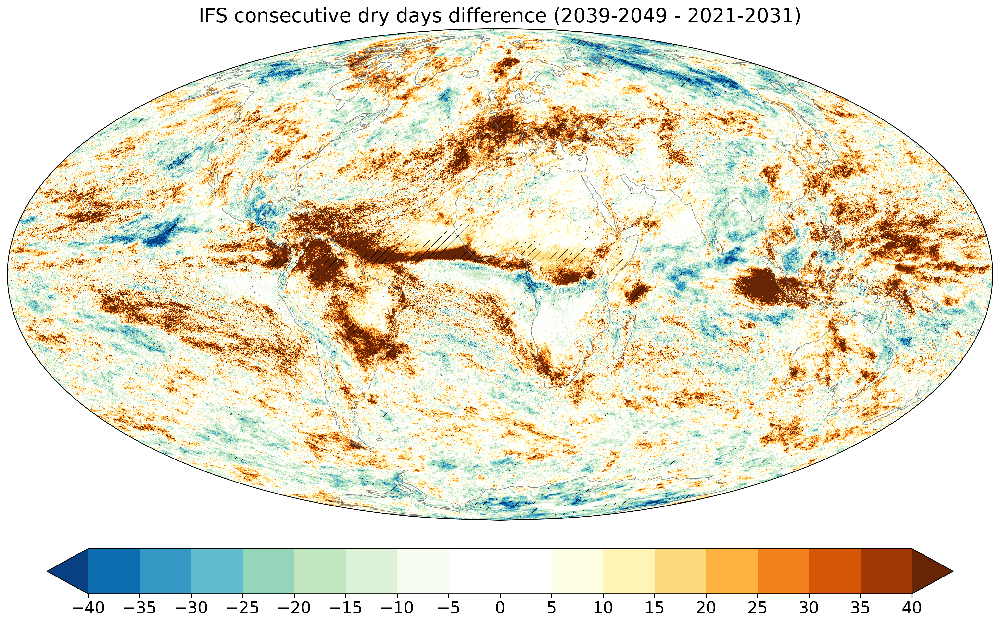

In [17]:
levels = np.arange(-40, 45, 5)
extend = 'both'
cmap = get_diverging_colormap(levels, cmap_neg='GnBu', cmap_pos='YlOrBr', return_colors=True, extend=extend)

fig, ax, map_ = default_plot(
    ifs_zoom9_change.squeeze(), 
    cmap=cmap, 
    levels=levels, 
    extend=extend,
    add_coastlines=True,
)
ax.set_title('IFS consecutive dry days difference (2039-2049 - 2021-2031)');

_, ax, hatch_contour = default_plot_hatch(
    ifs_zoom9_pvalue.squeeze(), 
    ax=ax,         # use the existing axis
    add_coastlines=False  # disable coastlines if they are already drawn
)
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_IFS_global_rast.pdf', format='pdf',bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_IFS_global_rast.png',bbox_inches='tight',dpi=600)


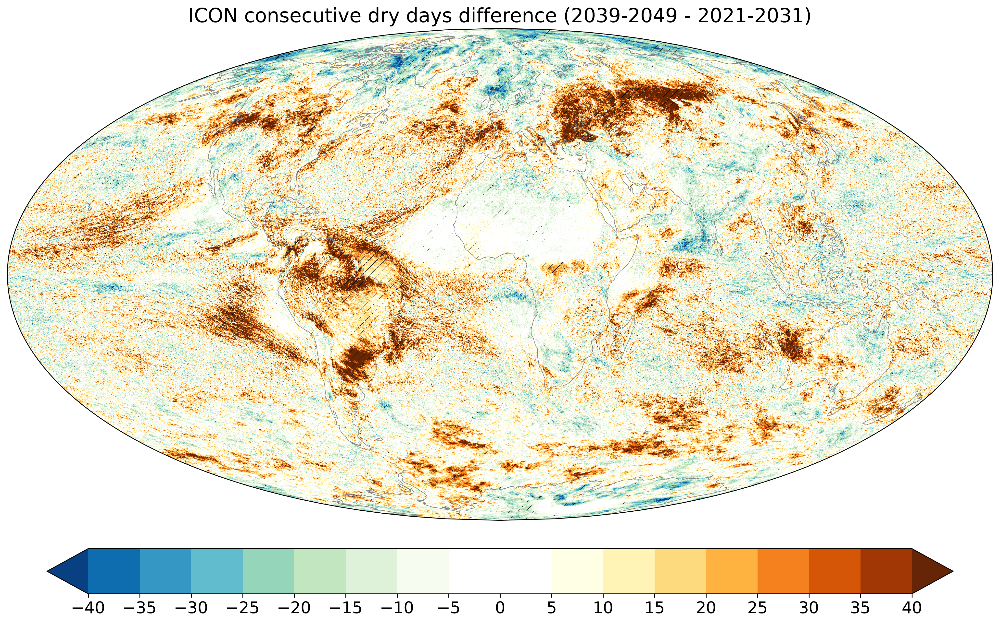

In [18]:
levels = np.arange(-40, 45, 5)
extend = 'both'
cmap = get_diverging_colormap(levels, cmap_neg='GnBu', cmap_pos='YlOrBr', return_colors=True, extend=extend)

fig, ax, map_ = default_plot(
    icon_zoom9_change.squeeze(), 
    cmap=cmap, 
    levels=levels, 
    extend=extend,
    add_coastlines=True,
)
ax.set_title('ICON consecutive dry days difference (2039-2049 - 2021-2031)');

_, ax, hatch_contour = default_plot_hatch(
    icon_zoom9_pvalue.squeeze(), 
    ax=ax,         # use the existing axis
    add_coastlines=False  # disable coastlines if they are already drawn
)
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_ICON_global_rast.pdf', format='pdf',bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_ICON_global_rast.png',bbox_inches='tight',dpi=600)


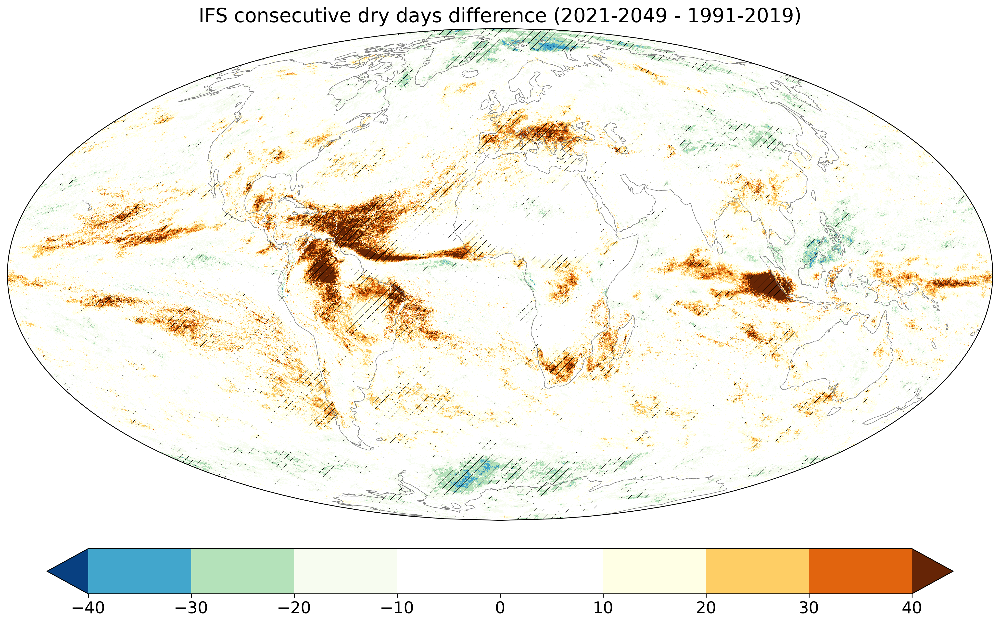

In [19]:
levels = np.arange(-40, 45, 10)
extend = 'both'
cmap = get_diverging_colormap(levels, cmap_neg='GnBu', cmap_pos='YlOrBr', return_colors=True, extend=extend)

fig, ax, map_ = default_plot(
    ifs_zoom9_hist_change.squeeze(), 
    cmap=cmap, 
    levels=levels, 
    extend=extend,
    add_coastlines=True,
)
ax.set_title('IFS consecutive dry days difference (2021-2049 - 1991-2019)');

_, ax, hatch_contour = default_plot_hatch(
    ifs_zoom9_hist_pvalue.squeeze(), 
    ax=ax,         # use the existing axis
    add_coastlines=False  # disable coastlines if they are already drawn
)
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_IFS_hist_global_rast.pdf', format='pdf',bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_IFS_hist_global_rast.png',bbox_inches='tight',dpi=600)


In [ ]:

def plot_cesm2_dry_days(trend_temp,pvalue_temp,levels, pval_threshold=0.05,
                          cmap='RdBu_r', title_units='Trend (units?)'):
    """
    Plot a global map of CESM2 trend data with hatching to indicate areas
    where the p-values (from pvalue_temp) are below a given threshold.
    
    Parameters
    ----------
    trend_temp : xarray.DataArray
        Trend data with (lat, lon) coordinates.
    pvalue_temp : xarray.DataArray
        p-value data with the same (lat, lon) coordinates.
    pval_threshold : float, optional
        Threshold for significance (default is 0.05).
    cmap : str or Colormap, optional
        Colormap for the trend data (default 'RdBu_r').
    title_units : str, optional
        Label for the colorbar.
    
    Returns
    -------
    fig, ax : tuple
        The matplotlib Figure and Axes objects.
    """
    # Squeeze extra dimensions if present.
    trend = trend_temp.squeeze()
    pvalue = pvalue_temp.squeeze()

    # Obtain the 1D latitude and longitude arrays.
    lat = trend['lat'].values
    lon = trend['lon'].values

    # --- Compute Grid Boundaries for pcolormesh ---
    # pcolormesh works best with boundaries, so we compute these to plot the trend.
    dlon = np.mean(np.diff(lon))
    dlat = np.mean(np.diff(lat))
    lon_b = np.concatenate(([lon[0] - dlon/2], lon + dlon/2))
    lat_b = np.concatenate(([lat[0] - dlat/2], lat + dlat/2))
    LonB, LatB = np.meshgrid(lon_b, lat_b)

    # --- Compute Cell Centers for the Hatching Overlay ---
    # Using cell centers (which have shape (nlat, nlon)) for the significance mask.
    Lon, Lat = np.meshgrid(lon, lat)
    #sig_mask = np.where(pvalue < pval_threshold, 1, np.nan)
    sig_mask = (pvalue < pval_threshold).astype(int)

    # --- Set Up the Map Projection and Figure ---
    # Use a Mollweide projection with central_longitude=0. Increase resolution for smoother curves.
    #proj = ccrs.Mollweide(central_longitude=0)
    #proj._threshold /= 1000.  # Increase transform resolution as in your example.
    #fig, ax = plt.subplots(figsize=(20, 10), subplot_kw={'projection': proj})
    #ax.set_global()


    # Set up a global map using Mollweide projection.
    proj = ccrs.Mollweide(central_longitude=0)

    fig, ax = plt.subplots(figsize=(20, 10), subplot_kw={'projection': proj})
    ax.set_global()
    
    # --- Define Geographic Extent ---
    # Use the boundaries computed for pcolormesh.
    extent = [lon_b.min(), lon_b.max(), lat_b.min(), lat_b.max()]

    # --- Define Color Levels and Normalization ---
    # Here we use levels similar to your example.
    norm = mpl.colors.BoundaryNorm(levels, ncolors=cmap.N, extend='both')
    #norm = mpl.colors.BoundaryNorm(levels, ncolors=cmap.N + 2, extend='both')

    # --- Plot the Trend Data Using pcolormesh ---
    im = ax.pcolormesh(LonB, LatB, trend.values, transform=ccrs.PlateCarree(),
                       cmap=cmap, norm=norm, shading='flat')
    im.set_edgecolor('face')
    mpl.rcParams['hatch.linewidth'] = 0.4

    # --- Overlay Significance Hatching ---
    # Use contourf on the cell centers with the same shape as sig_mask.
    # The additional option "corner_mask=True" forces the individual cell polygons.
    #ax.contourf(Lon, Lat, sig_mask, levels=[0.5, 1.5],
                #transform=ccrs.PlateCarree(), colors='none', hatches=['///'], 
                #alpha=0, corner_mask=True)


    ax.contourf(Lon, Lat, sig_mask, levels=[-0.5,0.5, 1.5],
                transform=ccrs.PlateCarree(), colors='none', hatches=['','///'], 
                alpha=0, corner_mask=True)
    # --- Add Coastlines and Borders ---
    coast_defaults = {'color': 'gray', 'lw': 0.5}
    ax.coastlines(resolution='50m', **coast_defaults)
    # Uncomment the line below to add country borders if desired.
    # ax.add_feature(cfeature.BORDERS, linewidth=0.5)

    # --- Add a Colorbar ---
    # The colorbar orientation and size is adjusted to match your example.
    cbar = plt.colorbar(im, ax=ax, orientation='vertical', shrink=0.8, fraction=0.03,
                        extend='both', ticks=levels)

    # --- Set the Title ---
    #ax.set_title('CESM2 consecutive dry days trend (2021-2049)')

    return fig, ax

# Example usage:
# fig, ax = plot_cesm2_dry_days(cesm2_trend, cesm2_pvalue, pval_threshold=0.05,
#                              cmap='RdBu_r', title_units='Trend (units?)')
# plt.savefig('/path/to/output/cesm2_dry_days_trend.pdf', format='pdf', bbox_inches='tight')
# plt.show()


In [30]:


def get_diverging_colormap(levels=12, cmap_neg='Blues', cmap_pos='Reds', 
                           middle_white=True, extend='both', return_colors=False):
    """
    Create a diverging colormap that combines colors from two base colormaps with a white
    middle. The white will cover the central intervals (e.g. from -0.5 to 0.5 when levels
    is np.arange(-4, 4.5, 0.5)).
    
    Parameters
    ----------
    levels : int or array-like
        If int, the total number of intervals; if array-like, the number of intervals is len(levels)-1.
    cmap_neg : str, optional
        Name of the colormap used for the negative portion.
    cmap_pos : str, optional
        Name of the colormap used for the positive portion.
    middle_white : bool, optional
        If True, insert white in the center.
    extend : str, optional
        Either 'both' or 'neither'. If 'both', the returned colormap will have set under/over colors.
    return_colors : bool, optional
        If True, return the raw array of colors; else return a ListedColormap.
        
    Returns
    -------
    cmap_final : ListedColormap or np.ndarray
        The diverging colormap.
    """
    # Determine total number of intervals:
    if isinstance(levels, int):
        nr = levels
    else:
        nr = len(levels) - 1

    white = None
    if nr % 2 == 0:
        nr //= 2
        if middle_white:
            nr -= 2
            white = np.array([[1, 1, 1, 1], [1, 1, 1, 1]])
    else:
        if middle_white:
            nr = (nr - 1) // 2
            white = np.array([[1, 1, 1, 1]])
        else:
            raise ValueError("Odd number of intervals with middle_white False is not supported.")
    
    if extend == 'both':
        nr += 2
    elif extend != 'neither':
        raise ValueError(f'extend has to be one of "both" or "neither", not {extend}')

    neg = get_listed_colormap(nr, cmap_neg, return_colors=True)[::-1]
    pos = get_listed_colormap(nr, cmap_pos, return_colors=True)

    if white is None:
        colors = np.concatenate([neg, pos])
    else:
        colors = np.concatenate([neg, white, pos])
    
    if return_colors:
        return colors
    if extend == 'neither':
        cmap_final = mpl.colors.ListedColormap(colors)
    else:
        cmap_final = mpl.colors.ListedColormap(colors)
        cmap_final.set_under(colors[0])
        cmap_final.set_over(colors[-1])
    return cmap_final




In [ ]:
print(np.shape(cesm2_pvalue))

In [ ]:
# Suppose you have levels defined as an array (e.g., boundaries for your data):
levels = np.arange(-40, 45, 10)
# And you want to create a colormap with a diverging scheme, using 'GnBu' for negatives
# and 'YlOrBr' for positives, with a white center, and with extend='both':
cmap = get_diverging_colormap(levels, cmap_neg='GnBu', cmap_pos='YlOrBr', 
                              middle_white=True, extend='both', return_colors=False)
fig, ax = plot_cesm2_dry_days(cesm2_change,cesm2_pvalue,levels,
                              pval_threshold=0.05, cmap=cmap,
                              title_units='Trend (units?)')

ax.set_title('CESM2 consecutive dry days difference (2039-2049 - 2021-2031)');

plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_CESM2_global.pdf',format='pdf', bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_CESM2_global.png',bbox_inches='tight',dpi=600)


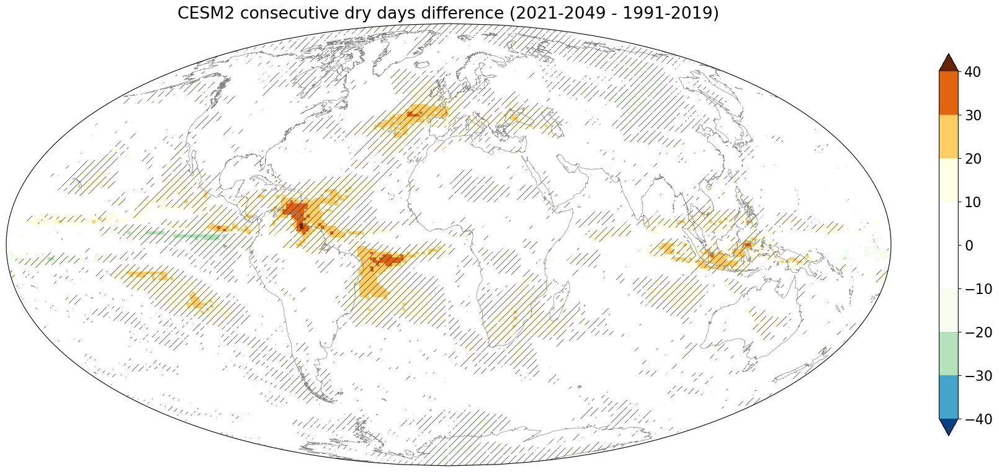

In [33]:
# Suppose you have levels defined as an array (e.g., boundaries for your data):
levels = np.arange(-40, 45, 10)
# And you want to create a colormap with a diverging scheme, using 'GnBu' for negatives
# and 'YlOrBr' for positives, with a white center, and with extend='both':
cmap = get_diverging_colormap(levels, cmap_neg='GnBu', cmap_pos='YlOrBr', 
                              middle_white=True, extend='both', return_colors=False)
fig, ax = plot_cesm2_dry_days(cesm2_hist_change,cesm2_hist_pvalue,levels,
                              pval_threshold=0.05, cmap=cmap,
                              title_units='Trend (units?)')

ax.set_title('CESM2 consecutive dry days difference (2021-2049 - 1991-2019)');

plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_CESM2_hist_global.pdf',format='pdf', bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/spatial_consect_dry_days_rel_diff_CESM2_hist_global.png',bbox_inches='tight',dpi=600)


In [ ]:
print((cesm2_pvalue-cesm2_hist_pvalue)

In [ ]:
print(cesm2_hist_pvalue.mean())

In [ ]:
pval_threshold=0.05

In [ ]:
sig_mask_1 = np.where(cesm2_pvalue < pval_threshold, 1, np.nan)
sig_mask_2 = np.where(cesm2_hist_pvalue < pval_threshold, 1, np.nan)



In [ ]:
print(sig_mask_1)

In [ ]:
print(np.nansum(sig_mask_1))

In [ ]:
print(np.nansum(sig_mask_2))